# Co-learn orbital dynamics and an ensemble filter

Can a position sensor teach us to estimate velocity? In this example we fit both an orbital dynamics model and the filter that assimilates the sensor readings. The only training target is the next noisy position. After training, we can compare the resulting velocity estimates with the simulated truth and an exact Kalman reference.

We adapt auto-differentiable ensemble 3DVar (AD-Ens3DVar) to a short synthetic orbit. Each trainable quantity has a home in Dynestyx. The orbital rate and the process noise belong to the model. The covariance used to assimilate observations belongs to a `SplitFilterConfig` subclass. One call to `dsx.condition` differentiates through both. [Auto-differentiable data assimilation, §§2 and 4.1](https://arxiv.org/html/2603.20891v2)

In [1]:
from dataclasses import dataclass
from time import perf_counter
from typing import NamedTuple

import jax
import jax.numpy as jnp
import jax.random as jr
import jax.scipy as jsp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import optax
from jaxtyping import PRNGKeyArray
from numpyro import distributions as dist
from numpyro.infer import SVI, Trace_ELBO, init_to_value
from numpyro.infer.autoguide import AutoNormal

import dynestyx as dsx
from dynestyx.inference.filter_interface import (
    FilterInputs,
    FilterOutputs,
    PredictedObservationOutputs,
)

## Generate position measurements

Use the six-state Clohessy–Wiltshire equations for relative motion in a rotating frame. If the state is $(x,y,z,v_x,v_y,v_z)$, its acceleration is $(3n^2 x + 2n v_y,-2n v_x,-n^2 z)$, where $n$ is the target's orbital rate. The exact transition over a sampling interval is the matrix exponential of the continuous generator times that interval.

We measure position in km and time in thousands of seconds, so one numerical unit of velocity is 1 m/s. The true rate is 0.0013 radians/s. This tutorial uses shorter trajectories and adds known diagonal process noise to the simulated motion. The true-parameter Kalman filter will then be an exact reference for our synthetic data. Separate calls to `dsx.simulate` generate independent training and held-out batches. The fit uses only the training observations. The held-out simulator states provide ground truth for the velocity comparisons.

In [2]:
step_size = 0.15  # 150 seconds
times = step_size * jnp.arange(40)
H = jnp.eye(3, 6)
R = 0.1 * jnp.eye(3)
initial_mean = jnp.array([1.0, 0.0, 0.6, 0.0, -1.2, 0.0])
initial_cov = jnp.diag(jnp.array([0.4, 0.4, 0.4, 0.2, 0.2, 0.2]) ** 2)


def orbital_transition(rate):
    coupling = jnp.diag(jnp.array([3.0, 0.0, -1.0])) * rate**2
    rotation = jnp.array([[0.0, 2.0, 0.0], [-2.0, 0.0, 0.0], [0.0, 0.0, 0.0]]) * rate
    generator = jnp.block([[jnp.zeros((3, 3)), jnp.eye(3)], [coupling, rotation]])
    return jsp.linalg.expm(step_size * generator)


class ModelParams(NamedTuple):
    log_rate: jax.Array
    log_process_sd: jax.Array


def make_model(params):
    return dsx.LTI_discrete(
        A=orbital_transition(jnp.exp(params.log_rate)),
        Q=jnp.diag(jnp.exp(2 * params.log_process_sd)),
        H=H,
        R=R,
        initial_mean=initial_mean,
        initial_cov=initial_cov,
    )


true_model_params = ModelParams(
    jnp.log(1.3), jnp.log(jnp.array([0.015] * 3 + [0.03] * 3))
)
true_model = make_model(true_model_params)


train = dsx.simulate(true_model, rng_key=jr.key(10), predict_times=times, n_simulations=8)
held_out = dsx.simulate(true_model, rng_key=jr.key(11), predict_times=times, n_simulations=8)
train_y = train.observations
test_states, test_y = held_out.states, held_out.observations

## Define the analysis on a filter config

Ensemble 3DVar estimates forecast uncertainty in two ways. The sample covariance $\widehat C_t$ responds to the current trajectory, but a small ensemble gives a noisy estimate. The positive semidefinite matrix $BB^\top$ is learned across training trajectories. Their blend supplies the innovation covariance and the gain

$$
C_t=(1-\alpha)BB^\top+\alpha\widehat C_t,\qquad S_t=HC_tH^\top+R,\qquad K_t=C_tH^\top S_t^{-1}.
$$

The ensemble updates use independently perturbed observations. To score the forecast we evaluate the **actual** measurement under $\mathcal N(H\bar x_t^-,S_t)$ before the update. The same innovation factor therefore determines both the observation score and how far each member moves. [AD-Ens3DVar update](https://arxiv.org/html/2603.20891v2#S2.SS1)

In [3]:
class Forecast(NamedTuple):
    members: jax.Array
    cumulative_score: jax.Array


class Analysis(NamedTuple):
    members: jax.Array
    cumulative_score: jax.Array
    prediction: PredictedObservationOutputs
    step_score: jax.Array


def sample_cov(members):
    anomalies = members - members.mean(axis=0)
    return anomalies.T @ anomalies / (len(members) - 1)


@dataclass(frozen=True, kw_only=True)
class Ens3DVarConfig(dsx.configs.SplitFilterConfig[Forecast, Analysis]):
    background_factor: jax.Array
    mixing_logit: jax.Array
    ensemble_size: int = 16

    def initialize(
        self,
        model: dsx.DynamicalModel,
        inputs: FilterInputs,
        *,
        key: PRNGKeyArray | None,
    ) -> Forecast:
        members = model.initial_condition.sample(key, (self.ensemble_size,))
        return Forecast(members, jnp.zeros(()))

    def predict(
        self,
        model: dsx.DynamicalModel,
        filtered: Analysis,
        inputs: FilterInputs,
        *,
        key: PRNGKeyArray | None,
    ) -> Forecast:
        def evolve(member, member_key):
            return model.state_evolution(
                member, inputs.u_prev, inputs.time_prev, inputs.time
            ).sample(member_key)

        members = jax.vmap(evolve)(filtered.members, jr.split(key, self.ensemble_size))
        return Forecast(members, filtered.cumulative_score)

    def update(
        self,
        model: dsx.DynamicalModel,
        prior: Forecast,
        inputs: FilterInputs,
        *,
        key: PRNGKeyArray | None,
    ) -> Analysis:
        obs = model.observation_model.params_at(inputs.time)
        H, R = obs.H, obs.R
        alpha = jax.nn.sigmoid(self.mixing_logit)
        background = self.background_factor @ self.background_factor.T
        forecast_cov = (1 - alpha) * background + alpha * sample_cov(prior.members)
        cross = forecast_cov @ H.T
        signal_cov = H @ cross
        innovation_cov = signal_cov + R
        chol = jnp.linalg.cholesky(innovation_cov)
        gain = jsp.linalg.cho_solve((chol, True), cross.T).T
        projected = prior.members @ H.T
        mean = projected.mean(axis=0)
        score = dist.MultivariateNormal(mean, scale_tril=chol).log_prob(inputs.y)
        noisy_y = inputs.y + jr.normal(key, projected.shape) @ jnp.linalg.cholesky(R).T
        updated = prior.members + (noisy_y - projected) @ gain.T
        prediction = PredictedObservationOutputs(
            mean=mean, cov=signal_cov, obs_cov=innovation_cov, noise_cov=R
        )
        return Analysis(updated, prior.cumulative_score + score, prediction, score)

    def gather_outputs(self, prior: Forecast, filtered: Analysis) -> FilterOutputs:
        return FilterOutputs(
            log_normalizing_constant=filtered.cumulative_score,
            filtered_means=filtered.members.mean(axis=0),
            filtered_covariances=sample_cov(filtered.members),
            predicted_observations=filtered.prediction,
            extra_outputs={"step_score": filtered.step_score},
        )

## Fit the dynamics with fixed or learned analysis hyperparameters

The first observation updates a draw from the initial Gaussian. At subsequent observations Dynestyx calls `predict` and `update` in sequence. We minimize the negative forecast log score on eight training sequences. Each sequence keeps the same ensemble key throughout optimization.

Both fits start with the same orbital rate, process noise, background factor $B$, and ensemble weight $\alpha$. **Dynamics only** updates the orbital rate and process noise while holding $B$ and $\alpha$ at their initial values. **Co-learned** also optimizes $B$ and $\alpha$. Both use the same optimizer, step count, and ensemble draws.

In [4]:
class AnalysisParams(NamedTuple):
    background_factor: jax.Array
    mixing_logit: jax.Array


initial_params = (
    ModelParams(jnp.log(0.65), jnp.log(0.07 * jnp.ones(6))),
    AnalysisParams(0.25 * jnp.eye(6), jnp.array(-0.8)),
)
train_keys = jr.split(jr.key(20), len(train_y))
test_keys = jr.split(jr.key(21), len(test_y))


def condition_trajectory(params, observations, key):
    dynamics, analysis = params
    config = Ens3DVarConfig(
        background_factor=analysis.background_factor,
        mixing_logit=analysis.mixing_logit,
        crn_seed=key,
    )
    with dsx.Filter(config):
        return dsx.condition(
            "orbit", make_model(dynamics), obs_times=times, obs_values=observations
        )


def loss(params, observations, keys):
    def score(ys, key):
        return condition_trajectory(params, ys, key).marginal_loglik

    return -jax.vmap(score)(observations, keys).mean() / len(times)


value_and_grad = jax.jit(jax.value_and_grad(loss))
initial_loss, gradients = value_and_grad(initial_params, train_y, train_keys)
for name, block in zip(("Model", "Filter"), gradients):
    assert all(bool(jnp.all(jnp.isfinite(leaf))) for leaf in jax.tree.leaves(block))
    norm = float(optax.global_norm(block))
    assert norm > 0
    print(f"{name} gradient norm {norm:.3f}")

# Synchronize one compiled gradient evaluation, excluding compilation and the optimizer.
jax.block_until_ready((initial_loss, gradients))
start = perf_counter()
jax.block_until_ready(value_and_grad(initial_params, train_y, train_keys))
print(
    f"Warm value_and_grad on {jax.devices()[0].platform}: {1e3 * (perf_counter() - start):.1f} ms"
)

Model gradient norm 9.962
Filter gradient norm 69.775
Warm value_and_grad on cpu: 3.1 ms


In [5]:
optimizer = optax.chain(optax.clip_by_global_norm(4.0), optax.adam(0.018))


def fit(objective, start_params, steps=90):
    @jax.jit
    def step(params, state, observations, keys):
        value, grads = jax.value_and_grad(objective)(params, observations, keys)
        updates, state = optimizer.update(grads, state, params)
        return optax.apply_updates(params, updates), state, value

    fitted = start_params
    state = optimizer.init(fitted)
    scores, path = [], [fitted]
    for _ in range(steps):
        fitted, state, value = step(fitted, state, train_y, train_keys)
        scores.append(value)
        path.append(fitted)
    scores.append(objective(fitted, train_y, train_keys))
    return fitted, jnp.stack(scores), jax.tree.map(lambda *xs: jnp.stack(xs), *path)


initial_model_params, fixed_analysis = initial_params


def dynamics_loss(model_params, observations, keys):
    return loss((model_params, fixed_analysis), observations, keys)


fitted_dynamics, dynamics_scores, dynamics_path = fit(
    dynamics_loss, initial_model_params
)
dynamics_only_params = (fitted_dynamics, fixed_analysis)
params, joint_scores, (joint_dynamics_path, joint_analysis_path) = fit(
    loss, initial_params
)

## Inspect the fit

The curves show the mean negative log score per three-dimensional observation and the parameters visited during training. The dashed line marks the generating orbital rate.

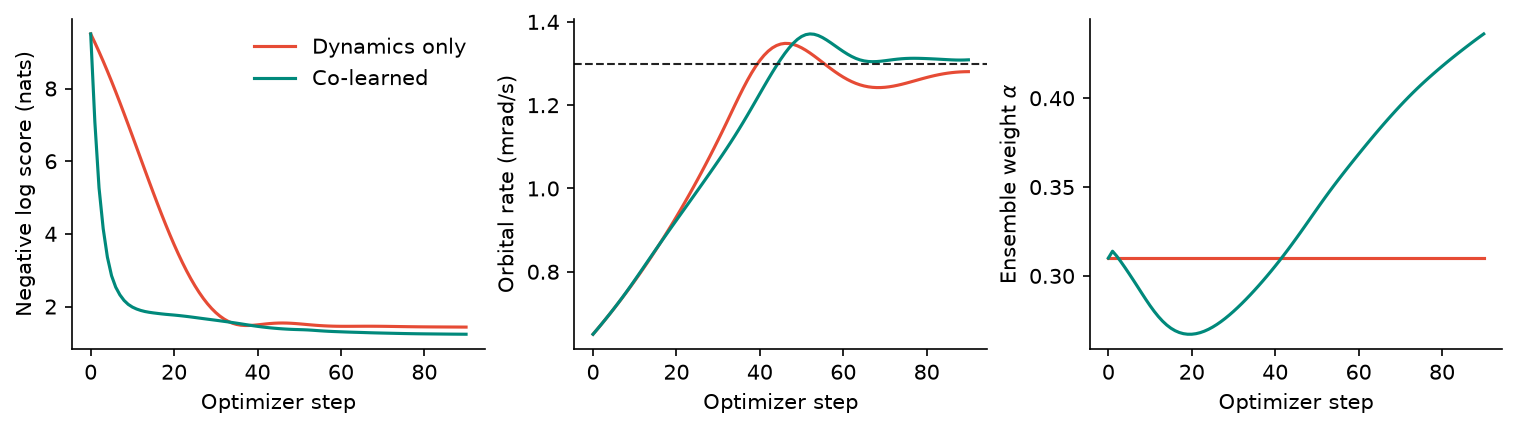

In [6]:
colors = {
    "Initialized": "#777777",
    "Dynamics only": "#E64B35",
    "Co-learned": "#00897B",
    "True-parameter KF": "#8C79B8",
}
plt.rcParams.update({"axes.linewidth": 0.8, "legend.frameon": False, "figure.dpi": 150})


def style_curves(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")


fig, axes = plt.subplots(1, 3, figsize=(10, 2.75), layout="constrained")
for label, scores, model_path, alpha in (
    (
        "Dynamics only",
        dynamics_scores,
        dynamics_path,
        jax.nn.sigmoid(fixed_analysis.mixing_logit),
    ),
    (
        "Co-learned",
        joint_scores,
        joint_dynamics_path,
        jax.nn.sigmoid(joint_analysis_path.mixing_logit),
    ),
):
    iteration = np.arange(len(scores))
    axes[0].plot(iteration, scores, color=colors[label], label=label)
    axes[1].plot(iteration, jnp.exp(model_path.log_rate), color=colors[label])
    axes[2].plot(
        iteration, jnp.broadcast_to(alpha, iteration.shape), color=colors[label]
    )
axes[1].axhline(jnp.exp(true_model_params.log_rate), color="#222222", ls="--", lw=1)
axes[0].legend()
for ax, ylabel in zip(
    axes,
    (
        "Negative log score (nats)",
        r"Orbital rate (mrad/s)",
        r"Ensemble weight $\alpha$",
    ),
):
    ax.set(xlabel="Optimizer step", ylabel=ylabel)
    style_curves(ax)
plt.show()

The contours are two-dimensional slices of the same training objective. In each panel we vary orbital rate and $\alpha$ while holding process noise and $B$ at that fit's final values. The common color scale makes the score levels comparable. The cross marks the fitted settings. For dynamics only, the optimizer could move horizontally along the dotted line at the fixed ensemble weight. The slices show how changing the filter can affect which dynamics the score favors.

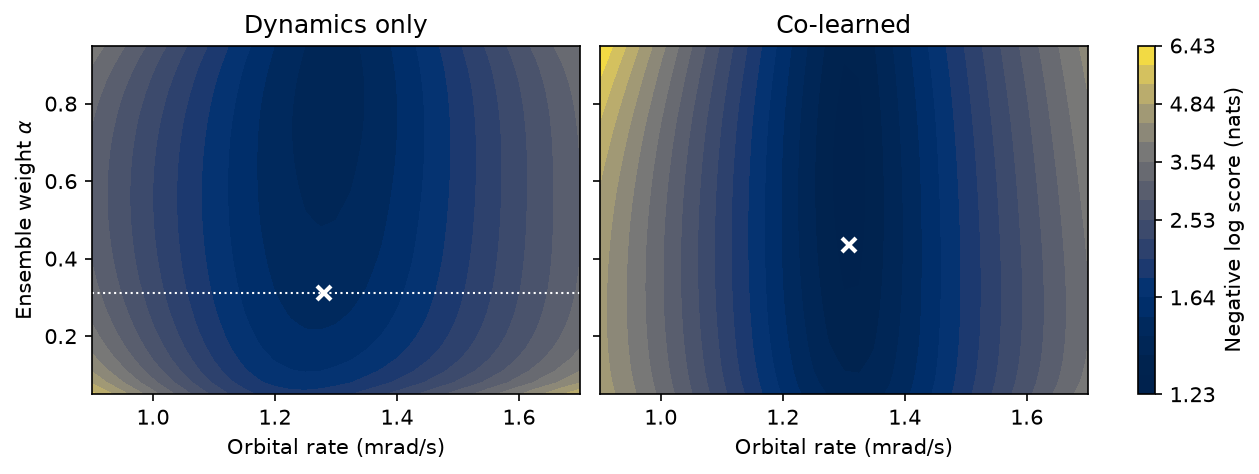

In [7]:
rates = jnp.linspace(0.9, 1.7, 33)  # mrad/s
weights = jnp.linspace(0.05, 0.95, 31)
rate_grid, weight_grid = jnp.meshgrid(rates, weights)
candidates = jnp.stack((rate_grid.ravel(), weight_grid.ravel()), axis=-1)


@jax.jit
def score_slice(fitted, points, observations, keys):
    model, analysis = fitted

    def at_point(point):
        rate, alpha = point
        return loss(
            (
                model._replace(log_rate=jnp.log(rate)),
                analysis._replace(mixing_logit=jsp.special.logit(alpha)),
            ),
            observations,
            keys,
        )

    return jax.lax.map(at_point, points, batch_size=16)


fits = {"Dynamics only": dynamics_only_params, "Co-learned": params}
surfaces = {
    label: np.asarray(score_slice(fitted, candidates, train_y, train_keys)).reshape(
        rate_grid.shape
    )
    for label, fitted in fits.items()
}
min_score = min(z.min() for z in surfaces.values())
max_score = max(z.max() for z in surfaces.values())
# Use finer contour intervals near the lowest scores.
levels = min_score + (max_score - min_score) * np.linspace(0, 1, 19) ** 2
fig, axes = plt.subplots(1, 2, figsize=(8.3, 3.05), sharey=True, layout="constrained")
for ax, (label, (model, analysis)) in zip(axes, fits.items()):
    contours = ax.contourf(
        rates, weights, surfaces[label], levels=levels, cmap="cividis"
    )
    alpha = jax.nn.sigmoid(analysis.mixing_logit)
    if label == "Dynamics only":
        ax.axhline(alpha, color="white", ls=":", lw=1)
    ax.plot(jnp.exp(model.log_rate), alpha, marker="x", ms=7, mew=2, color="white")
    ax.set(title=label, xlabel="Orbital rate (mrad/s)")
    ax.tick_params(direction="out")
axes[0].set_ylabel(r"Ensemble weight $\alpha$")
fig.colorbar(
    contours,
    ax=axes,
    label="Negative log score (nats)",
    ticks=levels[[0, 5, 9, 12, 15, 18]],
    format="%.2f",
)
plt.show()

## Estimate velocity on new trajectories

Evaluate all fits on eight held-out position sequences with fresh ensemble keys shared among the ensemble filters. The true-parameter KF uses the generating dynamics and gives an exact reference on the same observations. Velocity RMSE pools the three unobserved components, times, and trajectories. The log score measures one-step-ahead position forecasts in nats per three-dimensional observation.

In [8]:
def ensemble_estimate(params, ys, key):
    result = condition_trajectory(params, ys, key)
    return (
        result.states.filtered_means,
        result.marginal_loglik,
        result.extra_outputs["step_score"],
    )


def exact_estimate(ys):
    with dsx.Filter(dsx.configs.KFConfig(filter_source="cuthbert")):
        result = dsx.condition("orbit", true_model, obs_times=times, obs_values=ys)
    return jnp.stack([d.mean for d in result.dists]), result.marginal_loglik


evaluate = jax.jit(jax.vmap(ensemble_estimate, in_axes=(None, 0, 0)))
estimates = {}
for label, fitted in {"Initialized": initial_params, **fits}.items():
    means, scores, increments = evaluate(fitted, test_y, test_keys)
    np.testing.assert_allclose(scores, increments.sum(axis=-1), atol=1e-4, rtol=1e-5)
    estimates[label] = means, scores
estimates["True-parameter KF"] = jax.jit(jax.vmap(exact_estimate))(test_y)

print(f"{'Filter':18s}  {'Velocity RMSE (m/s)':>20s}  {'Mean log score (nats)':>22s}")
metrics = {}
for label, (means, scores) in estimates.items():
    sq_error = (means[..., 3:] - test_states[..., 3:]) ** 2
    metrics[label] = jnp.sqrt(sq_error.mean(axis=(1, 2))), scores / len(times)
    print(
        f"{label:18s}  {jnp.sqrt(sq_error.mean()):20.3f}  {scores.mean() / len(times):22.3f}"
    )

Filter               Velocity RMSE (m/s)   Mean log score (nats)
Initialized                        2.740                 -10.652
Dynamics only                      0.474                  -1.460
Co-learned                         0.337                  -1.316
True-parameter KF                  0.241                  -1.167


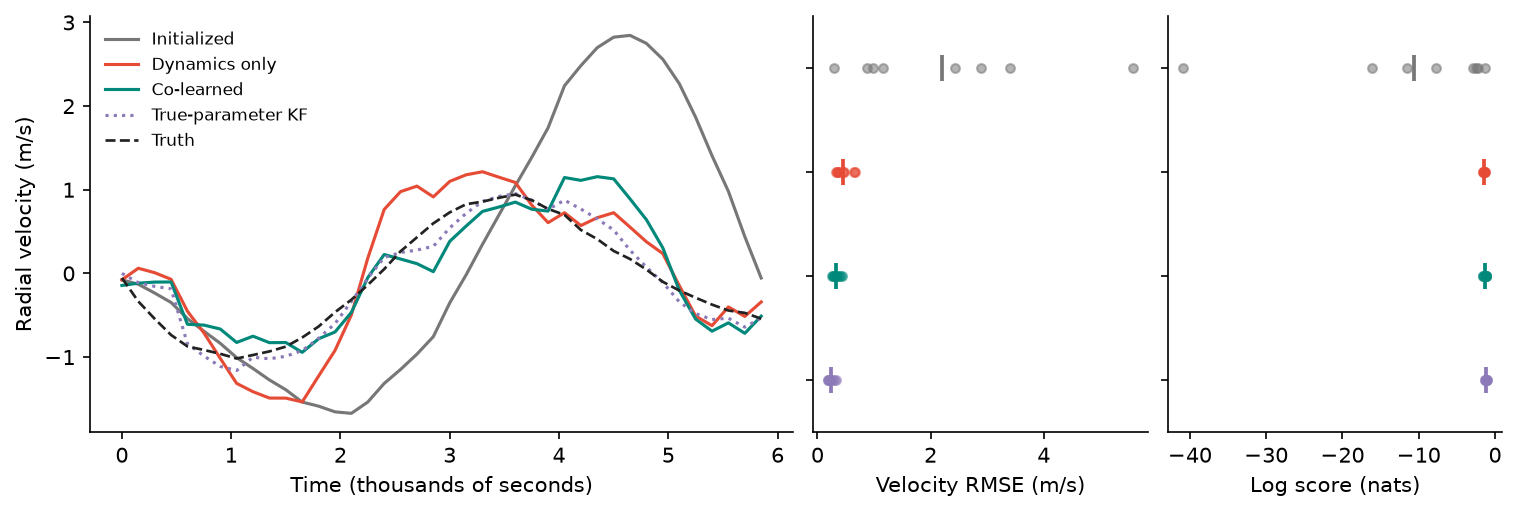

In [9]:
fig, (velocity_ax, error_ax, score_ax) = plt.subplots(
    1, 3, figsize=(10, 3.3), width_ratios=(2.1, 1, 1), layout="constrained"
)
for idx, (label, (means, _)) in enumerate(estimates.items()):
    color = colors[label]
    style = ":" if label == "True-parameter KF" else "-"
    velocity_ax.plot(times, means[0, :, 3], style, color=color, label=label)
    for ax, values in zip((error_ax, score_ax), metrics[label]):
        ax.scatter(values, np.full(len(values), idx), s=18, color=color, alpha=0.55)
        ax.scatter(jnp.mean(values), idx, marker="|", s=160, lw=1.8, color=color)
velocity_ax.plot(
    times, test_states[0, :, 3], "--", lw=1.3, color="#222222", label="Truth"
)
velocity_ax.set(xlabel="Time (thousands of seconds)", ylabel="Radial velocity (m/s)")
velocity_ax.legend(fontsize=8)
for ax, xlabel in zip(
    (error_ax, score_ax), ("Velocity RMSE (m/s)", "Log score (nats)")
):
    ax.set(
        xlabel=xlabel,
        yticks=range(len(estimates)),
        yticklabels=[],
        ylim=(len(estimates) - 0.5, -0.5),
    )
    style_curves(ax)
style_curves(velocity_ax)
plt.show()

The left panel shows the first held-out trajectory. Each dot in the right panels is one held-out trajectory, and the vertical marks show the mean of the dots. The table uses pooled velocity RMSE.

Dynamics-only training accounts for most of the improvement over initialization. Co-learning further reduces pooled velocity RMSE from **0.474 to 0.337 m/s** and improves the mean predictive log score from **−1.460 to −1.316** nats per observation.

## Use NumPyro to learn a distribution over the dynamics

Use `numpyro.sample` for the log orbital rate and log process-noise scales and let `AutoNormal` approximate their joint posterior with a mean-field guide. Mark $B$ and the mixing logit with `numpyro.param` in the **model**. SVI then learns one shared point estimate for each filter hyperparameter alongside the guide's location and scale parameters. For a variational dynamics-only fit, set `learn_analysis=False` to use constants in place of the two parameter sites.

Add the **sum** of forecast log scores as a single `numpyro.factor` so the likelihood and the prior are on the same scale. The factor uses the approximate ensemble score with fixed ensemble draws, so the resulting variational distribution targets the posterior defined by that approximate likelihood. [NumPyro SVI](https://num.pyro.ai/en/stable/svi.html) · [AutoNormal](https://num.pyro.ai/en/stable/autoguide.html#numpyro.infer.autoguide.AutoNormal)

In [10]:
def variational_model(observations, keys, *, learn_analysis=True):
    model_params = ModelParams(
        numpyro.sample("log_rate", dist.Normal(jnp.log(1.0), 0.5)),
        numpyro.sample(
            "log_process_sd",
            dist.Normal(initial_model_params.log_process_sd, 0.75).to_event(1),
        ),
    )
    analysis = fixed_analysis
    if learn_analysis:
        analysis = AnalysisParams(
            numpyro.param("background_factor", fixed_analysis.background_factor),
            numpyro.param("mixing_logit", fixed_analysis.mixing_logit),
        )
    total_score = (
        -len(observations)
        * len(times)
        * loss((model_params, analysis), observations, keys)
    )
    numpyro.factor("forecast_score", total_score)


guide = AutoNormal(
    variational_model,
    init_loc_fn=init_to_value(values=initial_model_params._asdict()),
    init_scale=0.05,
)
svi = SVI(variational_model, guide, optimizer, Trace_ELBO())
vi = svi.run(jr.key(30), 180, train_y, train_keys, progress_bar=False)
assert np.isfinite(vi.losses).all()
assert not np.allclose(vi.params["background_factor"], fixed_analysis.background_factor)
assert not np.allclose(vi.params["mixing_logit"], fixed_analysis.mixing_logit)

rate_quantiles = jnp.exp(guide.quantiles(vi.params, [0.05, 0.5, 0.95])["log_rate"])
print(
    f"Orbital rate median {rate_quantiles[1]:.3f} mrad/s "
    f"(90% variational interval {rate_quantiles[0]:.3f}–{rate_quantiles[2]:.3f})"
)
print(f"Optimized ensemble weight {jax.nn.sigmoid(vi.params['mixing_logit']):.3f}")

Orbital rate median 1.291 mrad/s (90% variational interval 1.259–1.324)
Optimized ensemble weight 0.659


### See which physical parameters the observations constrain

Compare the prior and variational marginal intervals in physical units. A narrow interval indicates concentration under the fitted approximate likelihood. The simulated values let us inspect whether the intervals include the truth for this fit. The mean-field guide uses independent normal marginals for the log parameters. The analysis covariance and ensemble weight are point estimates.

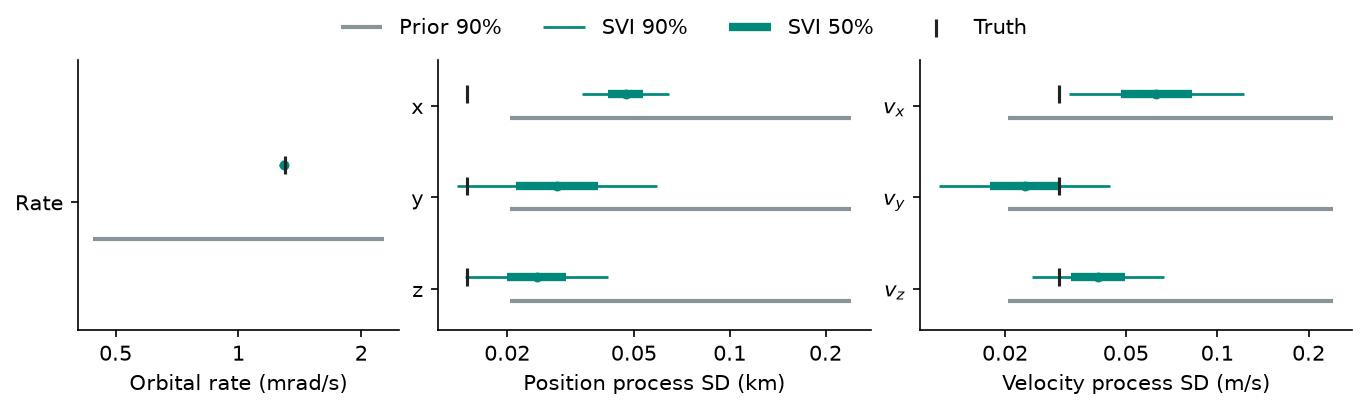

In [11]:
probabilities = jnp.array([0.05, 0.25, 0.50, 0.75, 0.95])
guide_quantiles = guide.quantiles(vi.params, probabilities)
rate_prior = jnp.exp(dist.Normal(jnp.log(1.0), 0.5).icdf(probabilities))
noise_prior = jnp.exp(
    dist.Normal(initial_model_params.log_process_sd, 0.75).icdf(probabilities[:, None])
)
rate_posterior = jnp.exp(guide_quantiles["log_rate"])
noise_posterior = jnp.exp(guide_quantiles["log_process_sd"])

point_color, mixture_color = "#C45636", "#00897B"
fig, axes = plt.subplots(
    1, 3, figsize=(9, 2.65), width_ratios=(1, 1.35, 1.35), layout="constrained"
)
for ax, prior, posterior, truth, labels, xlabel in zip(
    axes,
    (rate_prior[:, None], noise_prior[:, :3], noise_prior[:, 3:]),
    (rate_posterior[:, None], noise_posterior[:, :3], noise_posterior[:, 3:]),
    (
        jnp.exp(true_model_params.log_rate)[None],
        jnp.exp(true_model_params.log_process_sd[:3]),
        jnp.exp(true_model_params.log_process_sd[3:]),
    ),
    (("Rate",), ("x", "y", "z"), (r"$v_x$", r"$v_y$", r"$v_z$")),
    ("Orbital rate (mrad/s)", "Position process SD (km)", "Velocity process SD (m/s)"),
):
    row = np.arange(len(labels))
    ax.hlines(row + 0.13, prior[0], prior[-1], color="#89939A", lw=2, label="Prior 90%")
    ax.hlines(
        row - 0.13,
        posterior[0],
        posterior[-1],
        color=mixture_color,
        lw=1.3,
        label="SVI 90%",
    )
    ax.hlines(
        row - 0.13,
        posterior[1],
        posterior[-2],
        color=mixture_color,
        lw=4,
        label="SVI 50%",
    )
    ax.scatter(posterior[2], row - 0.13, color=mixture_color, s=14, zorder=3)
    ax.scatter(
        truth, row - 0.13, marker="|", color="#222222", s=80, zorder=4, label="Truth"
    )
    ax.set(
        xlabel=xlabel, yticks=row, yticklabels=labels, ylim=(len(labels) - 0.55, -0.5)
    )
    ax.set_xscale("log")
    style_curves(ax)
for ax, ticks in zip(
    axes, ([0.5, 1, 2], [0.02, 0.05, 0.1, 0.2], [0.02, 0.05, 0.1, 0.2])
):
    ax.set_xticks(ticks, labels=[f"{tick:g}" for tick in ticks])
    ax.minorticks_off()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=4)
plt.show()

### Propagate parameter uncertainty to held-out trajectories

Compare two uses of the **same SVI fit**. The plug-in filter uses the posterior median of the dynamics parameters. The mixture runs the filter at 256 guide draws, using the same learned analysis parameters and common ensemble random numbers. Each draw starts with equal weight on a new trajectory. For predicting $y_t$, weight the draws by their cumulative scores through $t-1$. For estimating the filtered velocity after seeing $y_t$, update those weights with its score. With equal initial weights, the mixture log score summed over time is the log-mean-exp of the draw-specific cumulative scores.

For velocity intervals, approximate each draw's conditional ensemble marginal by a Gaussian with its filtered mean and variance. Invert the weighted mixture CDF to get pointwise intervals. The plug-in intervals use the same conditional Gaussian approximation. Both include state uncertainty, and the mixture additionally propagates uncertainty in the dynamics.

In [12]:
svi_analysis = AnalysisParams(vi.params["background_factor"], vi.params["mixing_logit"])
median_model = ModelParams(**guide.median(vi.params))
model_draws = ModelParams(
    **guide.sample_posterior(jr.key(31), vi.params, sample_shape=(256,))
)


def filter_for_uq(model_params, ys, key):
    result = condition_trajectory((model_params, svi_analysis), ys, key)
    return (
        result.states.filtered_means[..., 3:],
        jnp.diagonal(result.states.filtered_covariances, axis1=-2, axis2=-1)[..., 3:],
        result.extra_outputs["step_score"],
    )


uq_trajectories = jax.vmap(filter_for_uq, in_axes=(None, 0, 0))


@jax.jit
def evaluate_draws(draws, observations, keys):
    return jax.lax.map(
        lambda model: uq_trajectories(model, observations, keys), draws, batch_size=8
    )


median_mean, median_var, median_steps = jax.jit(uq_trajectories)(
    median_model, test_y, test_keys
)
draw_means, draw_vars, draw_steps = evaluate_draws(model_draws, test_y, test_keys)

log_weights = jnp.cumsum(draw_steps, axis=-1)
filtered_weights = jax.nn.softmax(log_weights, axis=0)[..., None]
mixture_mean = jnp.sum(filtered_weights * draw_means, axis=0)
log_evidence = jsp.special.logsumexp(log_weights, axis=0) - jnp.log(len(draw_steps))
mixture_steps = jnp.diff(
    log_evidence, axis=-1, prepend=jnp.zeros_like(log_evidence[:, :1])
)
np.testing.assert_allclose(mixture_steps.sum(axis=-1), log_evidence[:, -1], atol=1e-5)


@jax.jit
def mixture_quantile(probability, means, variances, weights):
    sd = jnp.sqrt(jnp.maximum(variances, 1e-12))
    lower = jnp.min(means - 8 * sd, axis=0)
    upper = jnp.max(means + 8 * sd, axis=0)

    def bisect(_, bounds):
        lower, upper = bounds
        mid = (lower + upper) / 2
        cdf = jnp.sum(weights * jsp.special.ndtr((mid - means) / sd), axis=0)
        return jnp.where(cdf < probability, mid, lower), jnp.where(
            cdf < probability, upper, mid
        )

    lower, upper = jax.lax.fori_loop(0, 28, bisect, (lower, upper))
    return (lower + upper) / 2


interval_probs = jnp.array([0.05, 0.25, 0.75, 0.95])
normal_quantiles = jsp.special.ndtri(interval_probs)
median_bands = median_mean + normal_quantiles[:, None, None, None] * jnp.sqrt(
    median_var
)
mixture_bands = jax.vmap(mixture_quantile, in_axes=(0, None, None, None))(
    interval_probs, draw_means, draw_vars, filtered_weights
)

true_velocity = test_states[..., 3:]
summaries = (
    ("SVI median", point_color, median_mean, median_bands, median_steps),
    ("SVI mixture", mixture_color, mixture_mean, mixture_bands, mixture_steps),
)
print(
    f"{'Method':12s}  {'RMSE (m/s)':>10s}  {'Score (nats)':>12s}  {'90% coverage':>12s}  {'90% width (m/s)':>15s}"
)
for label, _, mean, bands, step_scores in summaries:
    low, _, _, high = bands
    coverage = jnp.mean((true_velocity >= low) & (true_velocity <= high))
    rmse = jnp.sqrt(jnp.mean((mean - true_velocity) ** 2))
    print(
        f"{label:12s}  {rmse:10.3f}  {step_scores.mean():12.3f}  {coverage:12.1%}  {(high - low).mean():15.3f}"
    )

Method        RMSE (m/s)  Score (nats)  90% coverage  90% width (m/s)
SVI median         0.337        -1.328         81.3%            0.875
SVI mixture        0.323        -1.305         85.2%            0.926


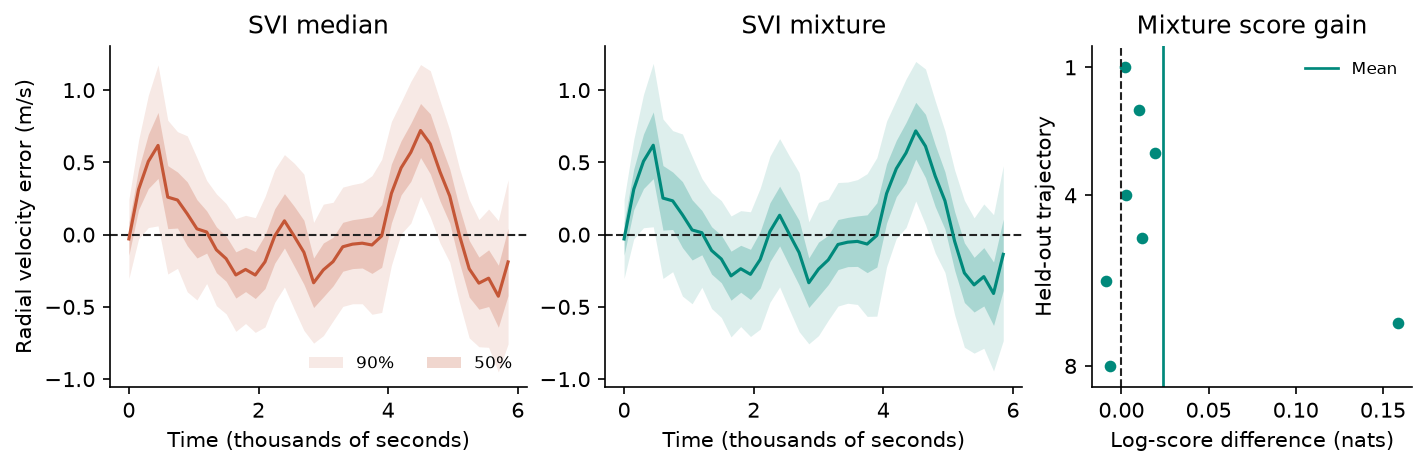

In [13]:
fig, axes = plt.subplots(
    1, 3, figsize=(9.4, 3), width_ratios=(1.3, 1.3, 1), layout="constrained"
)
path, radial = 0, 0  # First held-out trajectory, radial velocity
truth = true_velocity[path, :, radial]
for ax, (label, color, mean, bands, _) in zip(axes[:2], summaries):
    low90, low50, high50, high90 = bands[:, path, :, radial] - truth
    ax.fill_between(times, low90, high90, color=color, alpha=0.13, lw=0, label="90%")
    ax.fill_between(times, low50, high50, color=color, alpha=0.24, lw=0, label="50%")
    ax.axhline(0.0, color="#222222", ls="--", lw=1)
    ax.plot(times, mean[path, :, radial] - truth, color=color, lw=1.5)
    ax.set(title=label, xlabel="Time (thousands of seconds)")
    style_curves(ax)
axes[0].set_ylabel("Radial velocity error (m/s)")
ylim = (
    min(ax.get_ylim()[0] for ax in axes[:2]),
    max(ax.get_ylim()[1] for ax in axes[:2]),
)
for ax in axes[:2]:
    ax.set_ylim(ylim)
axes[0].legend(loc="lower right", ncols=2, fontsize=8)

score_gain = np.asarray((mixture_steps - median_steps).mean(axis=-1))
score_ax = axes[2]
score_ax.axvline(0.0, color="#222222", ls="--", lw=1)
score_ax.scatter(score_gain, np.arange(1, len(test_y) + 1), s=21, color=mixture_color)
score_ax.axvline(score_gain.mean(), color=mixture_color, lw=1.3, label="Mean")
score_ax.set(
    title="Mixture score gain",
    xlabel="Log-score difference (nats)",
    ylabel="Held-out trajectory",
    yticks=[1, 4, 8],
    ylim=(len(test_y) + 0.5, 0.5),
)
score_ax.legend(loc="best", fontsize=8)
style_curves(score_ax)
plt.show()

The velocity panels center each interval on the corresponding error relative to the simulated truth. The score panel shows the paired change in one-step-ahead log score on each held-out trajectory, where positive values favor integration. Coverage and width summarize pointwise velocity intervals over these eight trajectories from a single training fit.

The 90% interval for orbital rate (1.259–1.324 mrad/s) contains the true rate of 1.300. On the eight held-out trajectories, integrating the dynamics draws improves the mean forecast score by 0.023 nats per observation and reduces velocity RMSE from 0.337 to 0.323 m/s. The wider velocity intervals raise empirical coverage from 81.3% to 85.2%.